# Offer Targeting and Incrementality Analysis

This project uses synthetic campaign data to demonstrate an end-to-end marketing analytics workflow using DuckDB, SQL, pandas, and scikit-learn. The analysis builds historical customer features, validates campaign data, compares response-model candidates, measures the campaign's average treatment effect, and estimates which customer-campaign opportunities benefit most from treatment.

The analytical grain is one customer-campaign-observation-date record. All predictors are measured before the observation date, while activation and revenue outcomes are measured after it.

## Table of Contents

1. [Data Preparation and Feature Engineering](#section-1)
2. [Response Modeling](#section-2)
3. [Treatment Effect and Uplift Analysis](#section-3)
4. [Response Targeting vs. Uplift Targeting](#section-4)

<a id="section-1"></a>
## 1. Data Preparation and Feature Engineering

### Load and Validate Raw Data

Six synthetic source files represent customers, campaigns, campaign eligibility, treatment assignments, transactions, and offer-activation events. The files are loaded into DuckDB for SQL-based feature engineering and quality validation before modeling.

In [1]:
# ============================================================
# Load libraries for portfolio
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import duckdb
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
average_precision_score,
brier_score_loss,
log_loss,
roc_auc_score)

from sklearn.ensemble import GradientBoostingClassifier

print("Environment ready")
print("DuckDB:", duckdb.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Environment ready
DuckDB: 1.5.5
pandas: 2.0.2
scikit-learn: 1.2.2


In [2]:
# ============================================================
# Confirm Six Raw CSV Files
# ============================================================
from pathlib import Path

project_path = Path.cwd()
raw_data_path = project_path / "Raw Data"

print("Files found:", sorted(file.name for file in raw_data_path.glob("*.csv")))

# ============================================================
# Establish DuckDB connection
# ============================================================
database_path = project_path / "offer_portfolio.duckdb"

connection = duckdb.connect(str(database_path))

Files found: ['assignments.csv', 'campaigns.csv', 'customers.csv', 'eligibility.csv', 'offer_events.csv', 'transactions.csv']


In [3]:
# ============================================================
# Load and check all 6 raw files into DuckDB database
# ============================================================
table_names = ["customers","campaigns","eligibility","assignments","transactions","offer_events"]

for table_name in table_names:
    csv_path = raw_data_path/f"{table_name}.csv"
    
    connection.execute(f"""
        CREATE OR REPLACE TABLE {table_name} AS
        SELECT *
        FROM read_csv_auto(
        '{csv_path.as_posix()}',
        header = true)""")

    print(f"Loaded {table_name}")

# ============================================================
# Check 6 loaded tables, row counts and formats
# ============================================================
for table_name in table_names:
    row_count = connection.sql(f"""
    SELECT COUNT(*)
    FROM {table_name}""").fetchone()[0]
    
    print(f"{table_name}: {row_count:,} rows")
    var_description = connection.sql(f"DESCRIBE {table_name}").show()  

Loaded customers
Loaded campaigns
Loaded eligibility
Loaded assignments
Loaded transactions
Loaded offer_events
customers: 5,000 rows
┌─────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name     │ column_type │  null   │   key   │ default │  extra  │
│       varchar       │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ customer_id         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ signup_date         │ DATE        │ YES     │ NULL    │ NULL    │ NULL    │
│ region              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ age_band            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ acquisition_channel │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

campaigns: 12 rows
┌────────────────────┬─────────────┬─────────┬─────────┬─────────┬

In [4]:
# ============================================================
# Validation for Eligibility and Assignment table grain
# ============================================================
spine_qa = connection.sql("""
    SELECT
        'eligibility' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (customer_id, campaign_id)) AS unique_customer_campaigns,
        COUNT(*) - COUNT(DISTINCT (customer_id, campaign_id)) AS extra_rows
    FROM eligibility

    UNION ALL

    SELECT
        'assignments' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (customer_id, campaign_id)) AS unique_customer_campaigns,
        COUNT(*) - COUNT(DISTINCT (customer_id, campaign_id)) AS extra_rows
    FROM assignments""").df()

spine_qa = spine_qa.style.hide(axis="index").format({"total_rows": "{:,.0f}",
    "unique_customer_campaigns": "{:,.0f}",
    "extra_rows": "{:,.0f}"})

spine_qa

table_name,total_rows,unique_customer_campaigns,extra_rows
eligibility,"31,800","31,800",0
assignments,"31,800","31,800",0


In [5]:
# ============================================================
# Validate one matching assignment for every eligible customer-campaign record
# ============================================================
match_check = connection.sql("""
    SELECT
        COUNT(*) AS unmatched_rows
    FROM eligibility e
    FULL OUTER JOIN
        assignments a
        ON e.customer_id = a.customer_id
        AND e.campaign_id = a.campaign_id
    WHERE e.customer_id IS NULL
        OR a.customer_id IS NULL""").fetchone()[0]

print("Number of unmatched rows = " f"{match_check}")
if match_check == 0:
    print("PASS: Every eligibility row has exactly one matching assignment.")
else:
    print(f"FAIL: {match_check:,} unmatched customer-campaign rows found.")

# QA for automation
assert match_check == 0, (
    "Eligibility-assignment reconciliation failed: "
    f"{match_check:,} unmatched rows found.")

Number of unmatched rows = 0
PASS: Every eligibility row has exactly one matching assignment.


### Create the Model Population

The model population uses eligibility as its analytical spine, with one row per customer-campaign-observation-date record. Historical predictors are calculated using only transactions before the observation date, while activation and revenue outcomes are measured after that date.

- `activated_30d` includes activation events from the observation date through day 30.
- `revenue_90d` includes category-matched transaction revenue from the observation date through day 90.

In [6]:
# ============================================================
# Create persistent table in DuckDB
# ============================================================
connection.execute("""
CREATE OR REPLACE TABLE model_population AS 
-- Build historical transactions with eligible dates only before observation date (before targeting)
WITH historical_transactions AS (
	SELECT	
		e.customer_id,
		e.campaign_id,
        e.observation_date,
		COUNT(t.transaction_id) AS historical_order_count,
		COALESCE(SUM(t.revenue),0) AS historical_revenue,
		MAX(t.transaction_date) AS most_recent_transaction_date,
		DATEDIFF('day', MAX(t.transaction_date), e.observation_date) AS days_since_last_transaction
	FROM eligibility AS e
	-- Preserve the eligibility spine, including customers without prior transactions
	LEFT JOIN transactions AS t
		ON e.customer_id = t.customer_id AND t.transaction_date < e.observation_date
	GROUP BY e.customer_id, e.campaign_id, e.observation_date
),
activation_outcomes AS (
	SELECT
		e.customer_id,
		e.campaign_id,
        e.observation_date,
		MAX(CASE WHEN oe.event_id IS NOT NULL THEN 1 ELSE 0 END) AS activated_30d
	FROM eligibility AS e
	LEFT JOIN offer_events AS oe
		ON oe.customer_id = e.customer_id
		AND oe.campaign_id = e.campaign_id
		AND oe.event_type = 'activation'
		AND oe.event_timestamp >= e.observation_date
		AND oe.event_timestamp < e.observation_date + INTERVAL '31 days'
	GROUP BY e.customer_id, e.campaign_id, e.observation_date
),
revenue_outcomes AS (
	SELECT
		e.customer_id,
		e.campaign_id,
        e.observation_date,
		COALESCE(SUM(t.revenue),0) AS revenue_90d
	FROM eligibility AS e
	INNER JOIN campaigns AS cp
		ON e.campaign_id = cp.campaign_id
	LEFT JOIN transactions AS t
		ON e.customer_id = t.customer_id
		-- Attribute outcome revenue to the category promoted by the campaign
		AND cp.retailer_category = t.retailer_category 
		AND t.transaction_date >= e.observation_date
		AND t.transaction_date < e.observation_date + INTERVAL '91 days'
	GROUP BY e.customer_id,	e.campaign_id, e.observation_date
)
SELECT
	e.customer_id,
	e.campaign_id,
	e.observation_date,
	a.treatment_flag,
	c.region,
	c.age_band,
	c.acquisition_channel,
	cp.retailer_category,
	ht.historical_order_count,
	ht.historical_revenue,
	ht.most_recent_transaction_date,
	ht.days_since_last_transaction,
	ao.activated_30d,
	ro.revenue_90d
FROM eligibility AS e
INNER JOIN assignments AS a
	ON a.customer_id = e.customer_id 
    AND a.campaign_id = e.campaign_id
INNER JOIN customers AS c
	ON c.customer_id = e.customer_id
INNER JOIN campaigns AS cp
	ON cp.campaign_id = e.campaign_id
-- Derived CTEs should preserve eligibility; nulls reveal issues upstream
LEFT JOIN historical_transactions AS ht
	ON ht.customer_id = e.customer_id 
    AND ht.campaign_id = e.campaign_id
    AND ht.observation_date = e.observation_date
LEFT JOIN activation_outcomes AS ao
	ON ao.customer_id = e.customer_id 
    AND ao.campaign_id = e.campaign_id
    AND ao.observation_date = e.observation_date
LEFT JOIN revenue_outcomes AS ro
	ON ro.customer_id = e.customer_id 
    AND ro.campaign_id = e.campaign_id
    AND ro.observation_date = e.observation_date
    """)

model_population_head = connection.sql("""
    SELECT *
    FROM model_population""").df()

model_population_head.head()

,customer_id,campaign_id,observation_date,treatment_flag,region,age_band,acquisition_channel,retailer_category,historical_order_count,historical_revenue,most_recent_transaction_date,days_since_last_transaction,activated_30d,revenue_90d
0,1,1,2025-08-31,1,West,35-44,Referral,Grocery,3,86.37,2024-11-19,285,0,0.00
1,2,1,2025-08-31,1,Midwest,25-34,Paid Search,Grocery,4,138.86,2025-08-30,1,0,0.00
2,3,1,2025-08-31,1,Northeast,35-44,Paid Social,Grocery,4,291.95,2025-01-24,219,1,49.74
3,4,1,2025-08-31,1,Midwest,18-24,Partner,Grocery,6,196.14,2025-07-05,57,0,0.00
4,8,1,2025-08-31,1,Northeast,25-34,Paid Social,Grocery,6,262.28,2025-08-24,7,0,0.00


### Validate the Model Population

These checks confirm that the model population preserves the eligibility grain and row count, contains valid treatment and target values, and does not introduce unexpected missing or negative values. Missing recency is expected only when a customer has no prior transaction history.

In [7]:
# ============================================================
# Check that total row count and uniqueness is still preserved
# ============================================================
model_population_check = connection.sql("""
    SELECT
        (SELECT COUNT(*) FROM eligibility) AS eligibility_rows,
        COUNT(*) AS model_population_rows,
        COUNT(DISTINCT (customer_id, campaign_id, observation_date)) AS unique_model_population_rows,
        COUNT(*) - COUNT(DISTINCT (customer_id, campaign_id, observation_date))
            AS extra_rows,
        COUNT(*) - (SELECT COUNT(*) FROM eligibility) AS row_difference,
        CASE WHEN COUNT(*) = (SELECT COUNT(*) FROM eligibility)
            AND COUNT(*) = COUNT(DISTINCT (customer_id, campaign_id, observation_date))
            THEN 'PASS' ELSE 'FAIL' END AS population_check
    FROM model_population""").df()

model_population_check.style.hide(axis="index").format({
    "eligibility_rows": "{:,.0f}",
    "model_population_rows": "{:,.0f}",
    "unique_model_population_rows": "{:,.0f}",
    "extra_rows": "{:,.0f}",
    "row_difference": "{:,.0f}"})

eligibility_rows,model_population_rows,unique_model_population_rows,extra_rows,row_difference,population_check
"31,800","31,800","31,800",0,0,PASS


In [8]:
# ============================================================
# QA 1: Missings, range confirmation for binary vars, and negative revenue checks
# ============================================================
qa1 = connection.sql("""
SELECT
	SUM(CASE WHEN treatment_flag IS NULL THEN 1 ELSE 0 END) AS missing_treatment_flag,
    SUM(CASE WHEN region IS NULL THEN 1 ELSE 0 END) AS missing_region,
	SUM(CASE WHEN age_band IS NULL THEN 1 ELSE 0 END) AS missing_age_band,
    SUM(CASE WHEN acquisition_channel IS NULL THEN 1 ELSE 0 END) AS missing_acquisition_channel,
    SUM(CASE WHEN retailer_category IS NULL THEN 1 ELSE 0 END) AS missing_retailer_category,
	SUM(CASE WHEN historical_order_count IS NULL THEN 1 ELSE 0 END) AS missing_historical_order_count,
	SUM(CASE WHEN historical_revenue IS NULL THEN 1 ELSE 0 END) AS missing_historical_revenue,
	SUM(CASE WHEN activated_30d IS NULL THEN 1 ELSE 0 END) AS missing_activated_30d,
	SUM(CASE WHEN revenue_90d IS NULL THEN 1 ELSE 0 END) AS missing_revenue_90d,
    SUM(CASE WHEN days_since_last_transaction IS NULL THEN 1 ELSE 0 END) AS missing_days_since_last_transaction,
	SUM(CASE WHEN activated_30d NOT IN (0,1) THEN 1 ELSE 0 END) AS activated_30d_outside_range,
    SUM(CASE WHEN treatment_flag NOT IN (0, 1) THEN 1 ELSE 0 END) AS treatment_flag_outside_range,
	SUM(CASE WHEN historical_revenue < 0 THEN 1 ELSE 0 END) AS negative_historical_revenue,
	SUM(CASE WHEN revenue_90d < 0 THEN 1 ELSE 0 END) AS negative_revenue_90d
FROM model_population""").df()

qa1 = qa1.T.rename(columns={0: "check_count"})
qa1["check_count"] = qa1["check_count"].astype(int)
print(qa1)

# ============================================================
# QA 2: Recency consistency
# ============================================================
connection.sql("""
    SELECT
        SUM(CASE WHEN historical_order_count > 0 
            AND most_recent_transaction_date IS NULL THEN 1 ELSE 0 END) AS orders_with_missing_transaction_dates,
        SUM(CASE WHEN historical_order_count > 0 
            AND days_since_last_transaction IS NULL THEN 1 ELSE 0 END) AS orders_with_missing_recency,
        SUM(CASE WHEN historical_order_count = 0
            AND most_recent_transaction_date IS NOT NULL THEN 1 ELSE 0 END) AS transaction_date_with_no_orders,
        SUM(CASE WHEN historical_order_count = 0 
            AND days_since_last_transaction IS NOT NULL THEN 1 ELSE 0 END) AS recency_with_no_orders
    FROM model_population""").show()

                                     check_count
missing_treatment_flag                         0
missing_region                                 0
missing_age_band                               0
missing_acquisition_channel                    0
missing_retailer_category                      0
missing_historical_order_count                 0
missing_historical_revenue                     0
missing_activated_30d                          0
missing_revenue_90d                            0
missing_days_since_last_transaction         1090
activated_30d_outside_range                    0
treatment_flag_outside_range                   0
negative_historical_revenue                    0
negative_revenue_90d                           0
┌───────────────────────────────────────┬─────────────────────────────┬─────────────────────────────────┬────────────────────────┐
│ orders_with_missing_transaction_dates │ orders_with_missing_recency │ transaction_date_with_no_orders │ recency_with_no_orders │
│  

All grain, row-count, range, and recency-consistency checks passed. Missing recency was limited to customers without prior transaction history and is handled explicitly during preprocessing.

### Create the Modeling Datasets

Two modeling datasets are created from the validated population. The response-model dataset contains only treated records and predicts which opportunities are likely to activate when treated. The treatment-control dataset retains both groups for the later incrementality analysis.

In [9]:
# ============================================================
# Full treatment and control dataset
# ============================================================
connection.execute("""
CREATE OR REPLACE TABLE treatment_control_model_ds AS
    SELECT
        customer_id,
        campaign_id,
        observation_date,
        treatment_flag,
        region,
        age_band,
        acquisition_channel,
        retailer_category,
        historical_order_count,
        historical_revenue,
        days_since_last_transaction,
        activated_30d AS target
    FROM model_population""")

# ============================================================
# Response model dataset - treatment_flag = 1
# ============================================================
connection.execute("""
CREATE OR REPLACE TABLE treated_response_model_ds AS
    SELECT
        customer_id,
        campaign_id,
        observation_date,
        region,
        age_band,
        acquisition_channel,
        retailer_category,
        historical_order_count,
        historical_revenue,
        days_since_last_transaction,
        target
    FROM treatment_control_model_ds
    WHERE treatment_flag = 1""")
print("2 modeling data sets created")

2 modeling data sets created


In [10]:
# ============================================================
# Count rows, activations, and rates for both datasets
# ============================================================
modeling_dataset_check = connection.sql("""
    SELECT
        'treatment_control_model_ds' AS dataset,
        COUNT(*) AS rows,
        SUM(target) AS activations,
        AVG(target) AS activation_rate
    FROM treatment_control_model_ds

    UNION ALL

    SELECT
        'treated_response_model_ds' AS dataset,
        COUNT(*) AS rows,
        SUM(target) AS activations,
        AVG(target) AS activation_rate
    FROM treated_response_model_ds""").df()

modeling_dataset_check.style.hide(axis="index").format({
    "rows": "{:,.0f}",
    "activations": "{:,.0f}",
    "activation_rate": "{:.2%}"})

dataset,rows,activations,activation_rate
treatment_control_model_ds,"31,800","5,513",17.34%
treated_response_model_ds,"26,075","4,823",18.50%


In [11]:
# ============================================================
# Confirm that treated response model dataset contains the correct number of activations
# ============================================================
connection.sql("""
WITH test AS (
    SELECT
        (SELECT COUNT(*) FROM treated_response_model_ds) AS response_rows,
        (SELECT COUNT(*) FROM treatment_control_model_ds WHERE treatment_flag = 1) AS expected_treated_rows,
        (SELECT SUM(target) FROM treated_response_model_ds) AS response_activations,
        (SELECT SUM(target) FROM treatment_control_model_ds WHERE treatment_flag = 1) AS expected_treated_activations
)
SELECT
    response_rows,
    expected_treated_rows,
    response_activations,
    expected_treated_activations,
    response_rows - expected_treated_rows AS row_delta,
    response_activations - expected_treated_activations AS activation_delta,
    CASE WHEN response_rows = expected_treated_rows
        AND response_activations = expected_treated_activations THEN 'Pass' ELSE 'Fail' END AS pass_fail
FROM test""").show()

┌───────────────┬───────────────────────┬──────────────────────┬──────────────────────────────┬───────────┬──────────────────┬───────────┐
│ response_rows │ expected_treated_rows │ response_activations │ expected_treated_activations │ row_delta │ activation_delta │ pass_fail │
│     int64     │         int64         │        int128        │            int128            │   int64   │      int128      │  varchar  │
├───────────────┼───────────────────────┼──────────────────────┼──────────────────────────────┼───────────┼──────────────────┼───────────┤
│         26075 │                 26075 │                 4823 │                         4823 │         0 │                0 │ Pass      │
└───────────────┴───────────────────────┴──────────────────────┴──────────────────────────────┴───────────┴──────────────────┴───────────┘



<a id="section-2"></a>
## 2. Response Modeling

### Business Question: Among Treated Opportunities, Who Is Most Likely to Activate?

The response model ranks treated customer-campaign opportunities by their probability of activating within 30 days. Logistic Regression is evaluated as the interpretable baseline model, with Gradient Boosting used as a nonlinear challenger.

In [12]:
# ============================================================
# Treated response model as python dataframe
# ============================================================
treated_response_model = connection.sql("""
    SELECT *
    FROM treated_response_model_ds""").df()

# Confirm observation date is a datetime column
treated_response_model["observation_date"].info(verbose=True)

treated_response_model.head()

<class 'pandas.core.series.Series'>
RangeIndex: 26075 entries, 0 to 26074
Series name: observation_date
Non-Null Count  Dtype         
--------------  -----         
26075 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 203.8 KB


,customer_id,campaign_id,observation_date,region,age_band,acquisition_channel,retailer_category,historical_order_count,historical_revenue,days_since_last_transaction,target
0,1,1,2025-08-31,West,35-44,Referral,Grocery,3,86.37,285,0
1,2,1,2025-08-31,Midwest,25-34,Paid Search,Grocery,4,138.86,1,0
2,3,1,2025-08-31,Northeast,35-44,Paid Social,Grocery,4,291.95,219,1
3,4,1,2025-08-31,Midwest,18-24,Partner,Grocery,6,196.14,57,0
4,8,1,2025-08-31,Northeast,25-34,Paid Social,Grocery,6,262.28,7,0


In [13]:
# ============================================================
# Treated response summary - use to determine cutoff date
# ============================================================
summary = treated_response_model.groupby("observation_date").agg(
        treated_rows=("observation_date","count"),
        activations=("target","sum"),
        activation_rate=("target","mean")).reset_index()
summary.sort_values(by="observation_date").style.hide(axis="index").format({
    "treated_rows": "{:,.0f}",
    "activations": "{:,.0f}",
    "activation_rate": "{:.2%}"})

observation_date,treated_rows,activations,activation_rate
2025-08-31 00:00:00,"2,162",405,18.73%
2025-09-14 00:00:00,"2,166",416,19.21%
2025-09-28 00:00:00,"2,163",416,19.23%
2025-10-12 00:00:00,"2,166",396,18.28%
2025-10-26 00:00:00,"2,214",397,17.93%
2025-11-09 00:00:00,"2,159",396,18.34%
2025-11-23 00:00:00,"2,173",367,16.89%
2025-12-07 00:00:00,"2,227",424,19.04%
2025-12-21 00:00:00,"2,179",399,18.31%
2026-01-04 00:00:00,"2,139",373,17.44%


### Create the Chronological Training and Holdout Split

A chronological split evaluates performance on later campaigns. Training observations end on November 9, 2025, and holdout observations begin on December 21, 2025. The intervening periods form an outcome-maturity gap so that all 30-day training labels are complete before holdout scoring begins.

- `X` contains the categorical and historical behavioral predictors.
- `y` contains the binary `activated_30d` target.

In [14]:
# ============================================================
# Determine cut-off date
# ============================================================
train_end_date = pd.Timestamp("2025-11-09")
holdout_start_date = pd.Timestamp("2025-12-21")

train_mask = treated_response_model["observation_date"] <= train_end_date
holdout_mask = treated_response_model["observation_date"] >= holdout_start_date

# Need to make sure training outcome is complete before holdout scoring begins!
gap_mask = ((treated_response_model["observation_date"] > train_end_date)
            & (treated_response_model["observation_date"] < holdout_start_date))

response_train = treated_response_model.loc[train_mask].copy()
response_gap = treated_response_model.loc[gap_mask].copy()
response_holdout = treated_response_model.loc[holdout_mask].copy()

train_rows = response_train.shape[0]
print(f"Number of rows in training data = {train_rows:,}")

holdout_rows = response_holdout.shape[0]
print(f"Number of rows in holdout data = {holdout_rows:,}")

gap_rows = response_gap.shape[0]
print(f"Number of rows in gap data = {gap_rows:,}")

# ============================================================
# Do all of the treated rows = training rows + holdout rows + gap rows
# ============================================================
treated_rows = treated_response_model.shape[0]

if treated_rows==train_rows+holdout_rows+gap_rows:
    print("PASS:  Training rows + holdout rows + gap rows = Total Treated rows",
          f"\nTotal Rows =  {treated_rows:,}")
else:
    print("FAIL:  Rows do not add to total treated rows")

assert treated_rows==train_rows+holdout_rows+gap_rows, "FAIL:  Rows do not add to total treated rows"

Number of rows in training data = 13,030
Number of rows in holdout data = 8,645
Number of rows in gap data = 4,400
PASS:  Training rows + holdout rows + gap rows = Total Treated rows 
Total Rows =  26,075


In [15]:
# ============================================================
# Confirm latest training date is earlier than earliest holdout date
# ============================================================
print("Latest training observation date: ",response_train["observation_date"].max())
print("Earliest holdout observation date: ",response_holdout["observation_date"].min())

if response_train["observation_date"].max() + pd.Timedelta(days=31) <= response_holdout["observation_date"].min():
    print("PASS:  Training dates all fully mature")
else:
    print("FAIL: Training outcomes had not fully matured before holdout scoring begins")
assert response_train["observation_date"].max() + pd.Timedelta(days=31) <= response_holdout["observation_date"].min(),(
    "Training outcomes had not fully matured before holdout scoring began")

Latest training observation date:  2025-11-09 00:00:00
Earliest holdout observation date:  2025-12-21 00:00:00
PASS:  Training dates all fully mature


In [16]:
# ============================================================
# Calculate activations and rates for training and holdout
# ============================================================
response_activations = response_train["target"].sum()
response_activation_rate = response_train["target"].mean()

holdout_activations = response_holdout["target"].sum()
holdout_activation_rate = response_holdout["target"].mean()

activation_data = {"Dataset":["response_train","response_holdout"],
                   "Activations":[response_activations, holdout_activations],
                   "Activation_Rate":[response_activation_rate, holdout_activation_rate]}
activation_df = pd.DataFrame(activation_data)
activation_df.style.hide(axis="index").format({"Activations":"{:,}",
                                              "Activation_Rate":"{:.2%}"})

Dataset,Activations,Activation_Rate
response_train,"2,426",18.62%
response_holdout,"1,606",18.58%


In [17]:
# ============================================================
# Define categorical and numerical predictors
# ============================================================
categorical_features = [
    "region",
    "age_band",
    "acquisition_channel",
    "retailer_category"]
numerical_features = [
    "historical_order_count",
    "historical_revenue",
    "days_since_last_transaction"]

feature_cols = categorical_features + numerical_features
target_col = "target"

# ============================================================
# Create training and holdout datasets
# ============================================================
X_train = response_train.loc[:, feature_cols].copy()
X_holdout = response_holdout.loc[:, feature_cols].copy()

y_train = response_train.loc[:, target_col].copy()
y_holdout = response_holdout.loc[:, target_col].copy()

# ============================================================
# Validate the split
# ============================================================
assert len(X_train.index) > 0, ("The training dataset is empty")

assert len(X_holdout.index) > 0, ("The holdout dataset is empty")

assert len(treated_response_model.index) == (len(X_train.index) + len(X_holdout.index) + len(response_gap)), (
    f"Split row mismatch: source has {len(treated_response_model.index)} rows, "
    f"but training and holdout contain "
    f"{len(X_train.index) + len(X_holdout.index)} rows")

assert len(X_train.index) == len(y_train.index), (
    f"Training mismatch: X_train has {len(X_train.index)} rows, "
    f"but y_train has {len(y_train.index)} rows")

assert len(X_holdout.index) == len(y_holdout.index), (
    f"Holdout mismatch: X_holdout has {len(X_holdout.index)} rows, "
    f"but y_holdout has {len(y_holdout.index)} rows")

assert y_train.notna().all(), ("The training target contains missing values")

assert y_holdout.notna().all(), ("The holdout target contains missing values")

assert set(y_train.unique()).issubset({0, 1}), ("The training target contains values other than 0 and 1")

assert set(y_holdout.unique()).issubset({0, 1}), ("The holdout target contains values other than 0 and 1")

### Build the Logistic Regression Pipeline

The pipeline applies all preprocessing using training data only. Numerical missing values are filled with zero and accompanied by a missing-history indicator, numerical predictors are standardized, and categorical predictors are one-hot encoded before fitting the Logistic Regression model.

In [18]:
# ============================================================
# days_since_last_transaction was only column with NA - these will need imputation
    # Fill values with 0 and add indicator column instead of fill with mean/median to avoid shifting data
# ============================================================
recency_check = treated_response_model.copy()

recency_check["transaction_history"] = np.where(
    recency_check["historical_order_count"] == 0, "No prior orders", "Has prior orders")

recency_summary = recency_check.groupby("transaction_history").agg(rows=("customer_id", "size"),
                                                                   missing_recency=("days_since_last_transaction",
                                                                                    lambda values: values.isna().sum())
                                                                  ).reset_index()
recency_summary.style.hide(axis="index").format({
    "rows": "{:,.0f}",
    "missing_recency": "{:,.0f}"})

transaction_history,rows,missing_recency
Has prior orders,"25,176",0
No prior orders,899,899


In [19]:
# ============================================================
# Define numerical preprocessing for Logistic Regression
    # add_indicator will only add missing indicator to 
    # days_since_last_transaction column where 0 was used
# ============================================================
numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="constant", 
                                     fill_value=0,	
                                     add_indicator=True)),
           ("scaler", StandardScaler())])

# ============================================================
# Define categorical preprocessing for Logistic Regression
# ============================================================
categorical_encoder = OneHotEncoder(drop=None, handle_unknown="ignore")

# ============================================================
# Route each feature group through its preprocessing
# ============================================================
preprocessor = ColumnTransformer(
    transformers=[("numeric",
                   numeric_pipeline,
                   numerical_features),
                  ("categorical",
                   categorical_encoder,
                   categorical_features)], remainder="drop")

# ============================================================
# Combine preprocessing and logistic regression
# ============================================================
model_pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                                 ("classifier", LogisticRegression(penalty="l2",
                                                                   max_iter=1000, 
                                                                   random_state=42))])

# ============================================================
# Fit preprocessing and model on training data
# ============================================================
model_pipeline.fit(X_train, y_train)

# ============================================================
# Score the holdout data
# ============================================================
holdout_probabilities = model_pipeline.predict_proba(X_holdout)[:, 1]

# ============================================================
# Score the training data for model validation
# ============================================================
train_probabilities = model_pipeline.predict_proba(X_train)[:, 1]

# ============================================================
# Confirm convergence
# ============================================================
n_iter = model_pipeline.named_steps["classifier"].n_iter_[0]
print(n_iter)

31


### Build the Gradient Boosting Pipeline

Gradient Boosting is evaluated as a nonlinear challenger using the same training and holdout populations. Numerical predictors are imputed without scaling, while categorical predictors are one-hot encoded into the dense matrix required by the classifier.

In [20]:
# ============================================================
# Define numerical preprocessing for Gradient Boosting Classifier
# ============================================================
numeric_preprocess_GB = SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)

# ============================================================
# Define categorical preprocessing for Gradient Boosting Classifier
# ============================================================
categorical_encoder_GB = OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)

# ============================================================
# Route each feature group through its preprocessing
# ============================================================
preprocessor_GB = ColumnTransformer(
    transformers=[("numeric",
                   numeric_preprocess_GB,
                   numerical_features),
                  ("categorical",
                   categorical_encoder_GB,
                   categorical_features)], remainder="drop")

# ============================================================
# Combine preprocessing and Gradient Boosting Classifier
# ============================================================
model_pipeline_GB = Pipeline(steps=[("preprocessor", preprocessor_GB),
                                    ("classifier", GradientBoostingClassifier(random_state=42))])

# ============================================================
# Fit preprocessing and model on training data
# ============================================================
model_pipeline_GB.fit(X_train, y_train)

# ============================================================
# Score the holdout data
# ============================================================
holdout_probabilities_GB = model_pipeline_GB.predict_proba(X_holdout)[:, 1]

# ============================================================
# Score the training data for model validation
# ============================================================
train_probabilities_GB = model_pipeline_GB.predict_proba(X_train)[:, 1]

In [21]:
# ============================================================
# Evaluation function for validation
# ============================================================
def evaluate_probabilities(y_true, probabilities):
    return {"rows": len(y_true),
            "activation_rate": y_true.mean(),
            "roc_auc": roc_auc_score(y_true, probabilities),
            "average_precision": average_precision_score(y_true, probabilities),
            "log_loss": log_loss(y_true, probabilities),
            "brier_score": brier_score_loss(y_true, probabilities)}

In [22]:
# ============================================================
# Logistic Regression evaluation
# ============================================================
holdout_results = evaluate_probabilities(y_holdout, holdout_probabilities)
train_results = evaluate_probabilities(y_train, train_probabilities)

# No-skill baseline
baseline_series = pd.Series(y_train.mean(),
                            index=y_holdout.index,
                            name="baseline_probabilities")
baseline_results = evaluate_probabilities(y_holdout, baseline_series)

# ============================================================
# Gradient Boosting evaluation
# ============================================================
GB_holdout_results = evaluate_probabilities(y_holdout, holdout_probabilities_GB)
GB_train_results = evaluate_probabilities(y_train, train_probabilities_GB)

# Evaluation table for Logistic Regression and Gradient Boosting
evaluation_table = pd.DataFrame([{"dataset": "Training - Logistic Regression", **train_results},
				{"dataset": "Holdout - Logistic Regression", **holdout_results},
				{"dataset": "Training - Gradient Boosting", **GB_train_results},
				{"dataset": "Holdout - Gradient Boosting", **GB_holdout_results},
				{"dataset": "No-Skill Baseline", **baseline_results}])
evaluation_table.style.hide(axis="index").format({
    "rows": "{:,.0f}",
    "activation_rate": "{:.2%}",
    "roc_auc": "{:.4f}",
    "average_precision": "{:.4f}",
    "log_loss": "{:.4f}",
    "brier_score": "{:.4f}"})

dataset,rows,activation_rate,roc_auc,average_precision,log_loss,brier_score
Training - Logistic Regression,"13,030",18.62%,0.5568,0.2157,0.4770,0.1505
Holdout - Logistic Regression,"8,645",18.58%,0.5442,0.2109,0.4779,0.1506
Training - Gradient Boosting,"13,030",18.62%,0.6585,0.3500,0.4600,0.1447
Holdout - Gradient Boosting,"8,645",18.58%,0.5362,0.2061,0.4811,0.1517
No-Skill Baseline,"8,645",18.58%,0.5000,0.1858,0.4800,0.1513


### Model Selection: Logistic Regression vs. Gradient Boosting

Logistic Regression was selected as the response model. Its holdout ROC AUC of 0.5442 exceeded the no-skill baseline of 0.5000, indicating some ability to rank customer-campaign opportunities by their likelihood of activating when treated. Its holdout average precision of 0.2109 also exceeded the baseline of 0.1858, showing that the model concentrated actual activations more effectively near the top of its rankings.

The Logistic Regression holdout log loss of 0.4779 and Brier score of 0.1506 were both slightly lower than the baseline values of 0.4800 and 0.1513, indicating a modest improvement in probability accuracy. Its training and holdout results were also reasonably close, suggesting that the model generalized to the later holdout period without substantial overfitting.

The Gradient Boosting Classifier showed a considerable decline from training to holdout performance. Its ROC AUC decreased from 0.6585 in training to 0.5362 in holdout, while average precision declined from 0.3500 to 0.2061. This deterioration is consistent with overfitting and weaker generalization to the later period. Its holdout ROC AUC and average precision were also lower than those of Logistic Regression, and its holdout log loss and Brier score were worse than the no-skill baseline.

### Evaluate Targeting Usefulness

Standard evaluation metrics determine which model generalizes best, but they do not directly show how targeting performance changes by campaign depth. The holdout records are therefore ranked by predicted probability and divided into deciles to measure activation lift and capture.

In [23]:
# ============================================================
# Customer-campaign scoring table function for repeatable usage
# ============================================================
def build_decile_analysis(population_df,
                          probabilities,
                          target_col="target",
                          customer_id_col="customer_id",
                          number_of_deciles=10):
    
    """Create ranked scores, decile performance, lift, and capture."""

    # Confirm that every population row has exactly one probability.
    assert len(population_df.index) == len(probabilities), (f"Population has {len(population_df.index)} rows, "
        f"but probabilities contains {len(probabilities)} values")

    # Create independent copy of population and attach probabilities.
    ranked_df = population_df.copy()
    ranked_df["predicted_probabilities"] = probabilities

    # Rank scored rows from highest to lowest predicted activation probability.
    ranked_df = ranked_df.sort_values("predicted_probabilities", ascending=False).reset_index(drop=True)

    # Create model rank.
    ranked_df["model_rank"] = ranked_df.index + 1

    # Create ordered decile labels: decile1 is highest-scored.
    labels = [f"decile{i}" for i in range(1, number_of_deciles + 1)]
    ranked_df["score_decile"] = pd.qcut(ranked_df["model_rank"], q=number_of_deciles, labels=labels)

    # Calculate the overall holdout activation rate for lift comparisons.
    overall_activation_rate = ranked_df[target_col].mean()

    # Summarize scored row count, responses, and probabilities by score decile.
    decile_summary = ranked_df.groupby("score_decile", observed=True).agg(scored_rows=(customer_id_col, "count"),
                                                                          activations=(target_col, "sum"),
                                                                          average_predicted_probability=("predicted_probabilities", "mean"),
                                                                          actual_activation_rate=(target_col, "mean")).reset_index()

    # Calculate each decile's lift.
    decile_summary["lift"] = (decile_summary["actual_activation_rate"] / overall_activation_rate)

    # Calculate cumulative activations for capture rate.
    decile_summary["cumulative_activations"] = (decile_summary["activations"].cumsum())

    # Calculate the total number of observed holdout activations.
    total_activations = decile_summary["activations"].sum()

    # Calculate the share of all activations captured through each decile.
    decile_summary["cumulative_capture_rate"] = (decile_summary["cumulative_activations"] / total_activations)

    # Accumulate the number of customer-campaign combos targeted through each decile.
    decile_summary["cumulative_scored_rows"] = (decile_summary["scored_rows"].cumsum())

    # Calculate the total number of scored holdout rows.
    total_scored_rows = decile_summary["scored_rows"].sum()

    # Calculate the share of the population targeted through each decile.
    decile_summary["cumulative_targeting_share"] = (decile_summary["cumulative_scored_rows"] / total_scored_rows)

    # Calculate the activation rate among everyone targeted through each decile.
    decile_summary["cumulative_activation_rate"] = (decile_summary["cumulative_activations"]/ decile_summary["cumulative_scored_rows"])

    # Compare cumulative activation with the full holdout activation rate.
    decile_summary["cumulative_lift"] = (decile_summary["cumulative_activation_rate"]/ overall_activation_rate)

    # Confirm that decile aggregation did not lose or duplicate customers-campaign records.
    assert decile_summary["scored_rows"].sum() == len(ranked_df.index),"Decile aggregation changed the customer-campaign count"

    # Confirm that decile aggregation preserved the total activations.
    assert decile_summary["activations"].sum() == ranked_df[target_col].sum(), "Decile aggregation changed the activation count"

    # Return the ranked scored rows and full decile analysis,
    return ranked_df, decile_summary

In [24]:
# ============================================================
# Use scoring table function on Logistic Regression
# ============================================================
# Create holdout population slice
holdout_population = response_holdout[["customer_id", "campaign_id", "observation_date", "target"]].copy()

ranked_logreg_holdout, logreg_decile_summary = build_decile_analysis(
    population_df=holdout_population,
    probabilities=holdout_probabilities)

# ============================================================
# Use scoring table function on Gradient Boosting Classifier
# ============================================================
ranked_GB_holdout, GB_decile_summary = build_decile_analysis(
    population_df=holdout_population,
    probabilities=holdout_probabilities_GB)

#### Supporting Comparison: Decile Performance by Model

This table compares the cumulative ranking performance of both candidate models across the complete holdout population.

In [25]:
# ============================================================
# Combine results of Logistic Regression and Gradient Boosting Classifier
# ============================================================
model_comparison = pd.concat([logreg_decile_summary.assign(model="Logistic Regression"), 
                                                           GB_decile_summary.assign(model="Gradient Boosting")])

# Concise model-comparison summary:
final_cols = ["model", 
              "score_decile", 
              "lift", 
              "cumulative_lift", 
              "cumulative_capture_rate", 
              "cumulative_targeting_share"]

final_summary = model_comparison[final_cols].sort_values(by=["score_decile", "model"]).reset_index(drop=True)
final_summary.style.hide(axis="index").format({
    "lift": "{:.2f}",
    "cumulative_lift": "{:.2f}",
    "cumulative_capture_rate": "{:.2%}",
    "cumulative_targeting_share": "{:.2%}"})

model,score_decile,lift,cumulative_lift,cumulative_capture_rate,cumulative_targeting_share
Gradient Boosting,decile1,1.19,1.19,11.96%,10.01%
Logistic Regression,decile1,1.20,1.20,12.02%,10.01%
Gradient Boosting,decile2,1.24,1.22,24.35%,20.00%
Logistic Regression,decile2,1.15,1.17,23.47%,20.00%
Gradient Boosting,decile3,0.93,1.12,33.69%,30.01%
Logistic Regression,decile3,1.03,1.13,33.81%,30.01%
Gradient Boosting,decile4,1.03,1.10,44.02%,40.00%
Logistic Regression,decile4,1.11,1.12,44.89%,40.00%
Gradient Boosting,decile5,0.97,1.07,53.74%,50.01%
Logistic Regression,decile5,1.06,1.11,55.48%,50.01%


#### Selected Model: Logistic Regression Targeting Performance

The following table translates the selected model's rankings into targeting depth, activation capture, activation rate, and cumulative lift.

In [26]:
logreg_targeting_summary = logreg_decile_summary.loc[:,
    ["score_decile",
     "cumulative_targeting_share",
     "cumulative_capture_rate",
     "cumulative_activation_rate",
     "cumulative_lift"]]

logreg_targeting_summary.style.hide(axis="index").format({
    "cumulative_targeting_share": "{:.2%}",
    "cumulative_capture_rate": "{:.2%}",
    "cumulative_activation_rate": "{:.2%}",
    "cumulative_lift": "{:.2f}"})

score_decile,cumulative_targeting_share,cumulative_capture_rate,cumulative_activation_rate,cumulative_lift
decile1,10.01%,12.02%,22.31%,1.20
decile2,20.00%,23.47%,21.80%,1.17
decile3,30.01%,33.81%,20.93%,1.13
decile4,40.00%,44.89%,20.85%,1.12
decile5,50.01%,55.48%,20.61%,1.11
decile6,60.00%,65.50%,20.28%,1.09
decile7,69.99%,74.84%,19.86%,1.07
decile8,80.00%,83.00%,19.27%,1.04
decile9,89.99%,91.97%,18.98%,1.02
decile10,100.00%,100.00%,18.58%,1.00


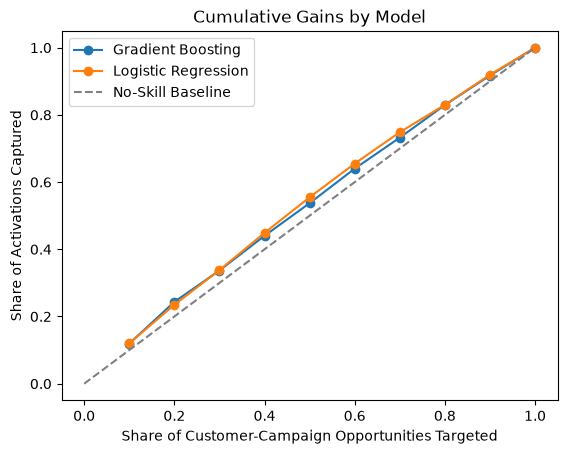

In [27]:
# ============================================================
# Create a cumulative gains chart:
# ============================================================
pivot_final_sum = final_summary.pivot(
    index="cumulative_targeting_share",
    columns="model",
    values="cumulative_capture_rate")
    
pivot_final_sum.plot(
    marker="o",
    title="Cumulative Gains by Model")


plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="No-Skill Baseline")

plt.xlabel("Share of Customer-Campaign Opportunities Targeted")
plt.ylabel("Share of Activations Captured")
plt.legend()
plt.show()

### Response-Model Conclusion

After selecting Logistic Regression for its stronger holdout performance relative to Gradient Boosting, the decile analysis shows a modest improvement in targeting performance. The top 10% of scored customer-campaign opportunities captured 12.02% of observed activations and had an activation rate 20% higher than the overall holdout rate. Expanding targeting to the top 20% captured 23.47% of observed activations and maintained a cumulative activation rate 17% higher than the overall holdout rate.

This lift is useful but moderate, so the model should be treated as a modest targeting enhancement rather than a highly predictive classifier.

<a id="section-3"></a>
## 3. Treatment Effect and Uplift Analysis

### Business Questions

1. Does treatment increase activation on average?
2. Which customer-campaign opportunities are most likely to activate because of the offer?

This section compares activation rates between treated and control opportunities to determine whether the offer increases activation on average. Because treatment was randomly assigned, the difference between the groups can be interpreted as the offer's average incremental effect.

The uplift-modeling phase then estimates how that incremental effect varies across opportunities, helping distinguish customers who activate because of treatment from those who are likely to activate regardless of treatment.

In [28]:
# ============================================================
# Convert Treatment-Control Data to a Python DataFrame
# ============================================================
treatment_control_model = connection.sql("""
    SELECT *
    FROM treatment_control_model_ds""").df()

# Confirm observation date is a datetime column
treatment_control_model["observation_date"].info(verbose=True)

treatment_control_model.head()

<class 'pandas.core.series.Series'>
RangeIndex: 31800 entries, 0 to 31799
Series name: observation_date
Non-Null Count  Dtype         
--------------  -----         
31800 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 248.6 KB


,customer_id,campaign_id,observation_date,treatment_flag,region,age_band,acquisition_channel,retailer_category,historical_order_count,historical_revenue,days_since_last_transaction,target
0,1,1,2025-08-31,1,West,35-44,Referral,Grocery,3,86.37,285,0
1,2,1,2025-08-31,1,Midwest,25-34,Paid Search,Grocery,4,138.86,1,0
2,3,1,2025-08-31,1,Northeast,35-44,Paid Social,Grocery,4,291.95,219,1
3,4,1,2025-08-31,1,Midwest,18-24,Partner,Grocery,6,196.14,57,0
4,8,1,2025-08-31,1,Northeast,25-34,Paid Social,Grocery,6,262.28,7,0


In [29]:
# ============================================================
# Initial treatment control checks
# ============================================================
treatment_control_model_check = treatment_control_model.groupby(["observation_date","treatment_flag"]).agg(scored_rows=("customer_id", "count"), 
                                                                                                            activations=("target", "sum"),
                                                                                                            activation_rate=("target", "mean")
                                                                                                          ).reset_index()
treatment_control_model_check

,observation_date,treatment_flag,scored_rows,activations,activation_rate
0,2025-08-31,0,488,59,0.120902
1,2025-08-31,1,2162,405,0.187327
2,2025-09-14,0,484,50,0.103306
3,2025-09-14,1,2166,416,0.192059
4,2025-09-28,0,487,72,0.147844
5,2025-09-28,1,2163,416,0.192325
6,2025-10-12,0,484,50,0.103306
7,2025-10-12,1,2166,396,0.182825
8,2025-10-26,0,436,52,0.119266
9,2025-10-26,1,2214,397,0.179313


In [30]:
# ============================================================
# Determine cut-off date
# ============================================================
train_end_date = pd.Timestamp("2025-11-09")
holdout_start_date = pd.Timestamp("2025-12-21")

tc_train_mask = treatment_control_model["observation_date"] <= train_end_date
tc_holdout_mask = treatment_control_model["observation_date"] >= holdout_start_date

# Need to make sure training outcome is complete before holdout scoring begins!
tc_gap_mask = ((treatment_control_model["observation_date"] > train_end_date)
            & (treatment_control_model["observation_date"] < holdout_start_date))

treatment_control_train = treatment_control_model.loc[tc_train_mask].copy()
treatment_control_gap = treatment_control_model.loc[tc_gap_mask].copy()
treatment_control_holdout = treatment_control_model.loc[tc_holdout_mask].copy()

tc_train_rows = treatment_control_train.shape[0]
print(f"Number of rows in training data = {tc_train_rows:,}")

tc_holdout_rows = treatment_control_holdout.shape[0]
print(f"Number of rows in holdout data = {tc_holdout_rows:,}")

tc_gap_rows = treatment_control_gap.shape[0]
print(f"Number of rows in gap data = {tc_gap_rows:,}")

# ============================================================
# Confirm training outcomes fully mature before holdout scoring begins
# ============================================================
if treatment_control_train["observation_date"].max()+pd.Timedelta('31days') <= treatment_control_holdout["observation_date"].min():
    print("Training data fully matures. Does not overlap with holdout")
else:
    print("Training data interferes with holdout. Does not mature")
    
assert (treatment_control_train["observation_date"].max() + pd.Timedelta(days=31)
    <= treatment_control_holdout["observation_date"].min()), "Training outcomes had not fully matured before holdout scoring began"

# ============================================================
# Do all of the rows in treatment and control = training rows + holdout rows + gap rows
# ============================================================
all_rows = treatment_control_model.shape[0]

if all_rows==tc_train_rows+tc_holdout_rows+tc_gap_rows:
    print("PASS:  Training rows + holdout rows + gap rows = Total Treatment/Control rows",
          f"\nTotal Rows =  {all_rows:,}")
else:
    print("FAIL:  Rows do not add to total Treatment/Control rows")

assert all_rows==tc_train_rows+tc_holdout_rows+tc_gap_rows, "FAIL:  Rows do not add to total Treatment/Control rows"

# ============================================================
# Confirm that treatment and control records both exist in training and holdout
# ============================================================
train_check = treatment_control_train.groupby(["treatment_flag"]).agg(scored_rows=("customer_id", "count")).reset_index()
holdout_check = treatment_control_holdout.groupby(["treatment_flag"]).agg(scored_rows=("customer_id", "count")).reset_index()

combined_check = pd.concat([train_check.assign(dataset="Training"),
                           holdout_check.assign(dataset="Holdout")],
                          ignore_index=True)

assert set(treatment_control_train["treatment_flag"].unique()) == {0, 1}, (
    "Training data does not contain both treatment and control records")

assert set(treatment_control_holdout["treatment_flag"].unique()) == {0, 1}, (
    "Holdout data does not contain both treatment and control records")
combined_check = combined_check[["dataset","treatment_flag","scored_rows"]]
combined_check.style.hide(axis="index").format({"scored_rows":"{:,}"})

Number of rows in training data = 15,900
Number of rows in holdout data = 10,600
Number of rows in gap data = 5,300
Training data fully matures. Does not overlap with holdout
PASS:  Training rows + holdout rows + gap rows = Total Treatment/Control rows 
Total Rows =  31,800


dataset,treatment_flag,scored_rows
Training,0,"2,870"
Training,1,"13,030"
Holdout,0,"1,955"
Holdout,1,"8,645"


### Part 1: Does Treatment Work on Average?

This section compares activation rates between treated and control customer-campaign opportunities to estimate the average treatment effect. A 95% confidence interval measures uncertainty around the estimated lift and determines whether it is statistically distinguishable from zero.

In [31]:
# ============================================================
# Did treatment increase activation on average in the out-of-time holdout population?
# ============================================================
treatment_control_holdout_check = treatment_control_holdout.groupby(["treatment_flag"]).agg(scored_rows=("customer_id", "count"), 
                                                                                            activations=("target", "sum"),
                                                                                            activation_rate=("target", "mean")
                                                                                            ).reset_index()
treatment_activation_rate = treatment_control_holdout_check.loc[
    treatment_control_holdout_check["treatment_flag"]==1,"activation_rate"].values[0]
control_activation_rate = treatment_control_holdout_check.loc[
    treatment_control_holdout_check["treatment_flag"]==0,"activation_rate"].values[0]

absolute_lift = (treatment_activation_rate - control_activation_rate)
print(f"Absolute lift, treatment activation minus control activation, is:  {absolute_lift*100:.2f} pp")
                 
relative_lift = (absolute_lift/control_activation_rate)
print(f"Relative lift, absolute lift divided by control rate, is:  {relative_lift:.2%}")

Absolute lift, treatment activation minus control activation, is:  6.91 pp
Relative lift, absolute lift divided by control rate, is:  59.29%


In [32]:
# ============================================================
# Is the overall positive lift broadly present across the holdout periods, or is it being driven by only one campaign?
# ============================================================
temp_tc = treatment_control_holdout.copy()
temp_tc["treatment_rows"] = np.where(treatment_control_holdout["treatment_flag"]==1,1,0)
temp_tc["control_rows"] = np.where(treatment_control_holdout["treatment_flag"]==0,1,0)

temp_tc["treatment_target"] = np.where(treatment_control_holdout["treatment_flag"]==1,
                                       treatment_control_holdout["target"],0)
temp_tc["control_target"] = np.where(treatment_control_holdout["treatment_flag"]==0,
                                     treatment_control_holdout["target"],0)

tc_date_check = temp_tc.groupby(["observation_date"]).agg(treatment_scored_rows=("treatment_rows", "sum"), 
                                                          control_scored_rows=("control_rows", "sum"),
                                                          treatment_activations=("treatment_target", "sum"),
                                                          control_activations=("control_target", "sum")
                                                          ).reset_index()

tc_date_check["treatment_activation_rate"] = (tc_date_check["treatment_activations"]/
                                              tc_date_check["treatment_scored_rows"])
tc_date_check["control_activation_rate"] = (tc_date_check["control_activations"]/
                                            tc_date_check["control_scored_rows"])
tc_date_check["absolute_lift_pp"] = (tc_date_check["treatment_activation_rate"] -
                                     tc_date_check["control_activation_rate"])*100

tc_date_check.style.hide(axis="index").format({
    "treatment_scored_rows": "{:,.0f}",
    "control_scored_rows": "{:,.0f}",
    "treatment_activations": "{:,.0f}",
    "control_activations": "{:,.0f}",
    "treatment_activation_rate": "{:.2%}",
    "control_activation_rate": "{:.2%}",
    "absolute_lift_pp": "{:.2f} pp"})

observation_date,treatment_scored_rows,control_scored_rows,treatment_activations,control_activations,treatment_activation_rate,control_activation_rate,absolute_lift_pp
2025-12-21 00:00:00,"2,179",471,399,58,18.31%,12.31%,6.00 pp
2026-01-04 00:00:00,"2,139",511,373,58,17.44%,11.35%,6.09 pp
2026-01-18 00:00:00,"2,155",495,416,54,19.30%,10.91%,8.39 pp
2026-02-01 00:00:00,"2,172",478,418,58,19.24%,12.13%,7.11 pp


Across the full holdout population, treatment increased activation by 6.9 percentage points. To determine whether this result was driven by a single campaign, treatment and control activation rates were also compared across the four holdout campaigns. All four campaigns produced positive absolute lift, ranging from 6.00 to 8.39 percentage points. Treatment and control group sizes were also reasonably consistent across the campaigns.

These results suggest that the overall treatment lift was broadly consistent and was not driven by one unusually strong campaign.

In [33]:
# ============================================================
# Calculate standard error and confidence interval to determine 
# whether the overall absolute lift could reasonably be explained by sampling variation.
# ============================================================
overall_treatment_rows = temp_tc["treatment_rows"].sum()
overall_control_rows = temp_tc["control_rows"].sum()

overall_treatment_ar = temp_tc["treatment_target"].sum() / overall_treatment_rows
overall_control_ar = temp_tc["control_target"].sum() / overall_control_rows

standard_error = np.sqrt((overall_treatment_ar *(1-overall_treatment_ar)/overall_treatment_rows) + 
                         (overall_control_ar *(1-overall_control_ar)/overall_control_rows))

upper_confidence_bound = (overall_treatment_ar - overall_control_ar) + 1.96 * standard_error
lower_confidence_bound = (overall_treatment_ar - overall_control_ar) - 1.96 * standard_error

print(f"Standard error is: {standard_error:.5%}")
print(f"Confidence interval is ({lower_confidence_bound:.5%},{upper_confidence_bound:.5%})")

Standard error is: 0.83782%
Confidence interval is (5.27268%,8.55693%)


The 95% confidence interval for the 6.9-percentage-point treatment lift ranged from 5.27 to 8.56 percentage points. Because the interval does not include zero, the positive lift is unlikely to be explained by ordinary sampling variation.

We therefore conclude that treatment increased activation overall, the effect was positive across all four holdout campaigns, and the overall treatment effect was statistically significant.

### Part 2: Who Benefits Most From Treatment?

Treatment works on average, but its effect may differ across customer-campaign opportunities. A two-model approach estimates that difference:

- The treated model estimates activation probability if treatment is applied.
- The control model estimates activation probability without treatment.
- Estimated uplift is the treated probability minus the control probability.

In [34]:
# ============================================================
# Create modeling datasets
# ============================================================
X_treated_train = treatment_control_train.loc[
    treatment_control_train["treatment_flag"]==1, feature_cols].copy()
y_treated_train = treatment_control_train.loc[
    treatment_control_train["treatment_flag"]==1, target_col].copy()

X_control_train = treatment_control_train.loc[
    treatment_control_train["treatment_flag"]==0, feature_cols].copy()
y_control_train = treatment_control_train.loc[
    treatment_control_train["treatment_flag"]==0, target_col].copy()

# ============================================================
# QA checks to validate modeling datasets
# ============================================================
assert len(X_treated_train.index) > 0, ("The training dataset is empty")

assert len(X_control_train.index) > 0, ("The control dataset is empty")

assert len(X_treated_train.index) == len(y_treated_train.index), (
    f"Training mismatch: X_treated_train has {len(X_treated_train.index)} rows, "
    f"but y_treated_train has {len(y_treated_train.index)} rows")

assert len(X_control_train.index) == len(y_control_train.index), (
    f"Control mismatch: X_control_train has {len(X_control_train.index)} rows, "
    f"but y_control_train has {len(y_control_train.index)} rows")

assert y_treated_train.notna().all(), ("The y_treated_train target contains missing values")

assert y_control_train.notna().all(), ("The y_control_train target contains missing values")

assert set(y_treated_train.unique()) == {0, 1}, ("The y_treated_train target must contain values 0 and 1")

assert set(y_control_train.unique()) == {0, 1}, ("The y_control_train target must contain values 0 and 1")

assert len(X_treated_train.index) == len(X_train.index), (
    f"Treated training data has {len(X_treated_train.index)} rows, "
    f"but treated response model training data has {len(X_train.index)} rows")

assert y_treated_train.sum() == y_train.sum(), (
    f"Treated training activation has {y_treated_train.sum()} activations, "
    f"but treated response model activation has {y_train.sum()} activations")

#### Build the Control Model

The selected response model already estimates activation probability under treatment. A separate Logistic Regression model is now trained on control records using the same predictors and preprocessing structure. Together, the two models estimate each opportunity's activation probability with and without treatment.

In [35]:
# ============================================================
# Define numerical preprocessing for Logistic Regression
    # add_indicator will only add missing indicator to 
    # days_since_last_transaction column where 0 was used
# ============================================================
control_numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="constant", 
                                     fill_value=0,	
                                     add_indicator=True)),
           ("scaler", StandardScaler())])

# ============================================================
# Define categorical preprocessing for Logistic Regression
# ============================================================
control_categorical_encoder = OneHotEncoder(drop=None, handle_unknown="ignore")

# ============================================================
# Route each feature group through its preprocessing
# ============================================================
control_preprocessor = ColumnTransformer(
    transformers=[("numeric",
                   control_numeric_pipeline,
                   numerical_features),
                  ("categorical",
                   control_categorical_encoder,
                   categorical_features)], remainder="drop")

# ============================================================
# Combine preprocessing and logistic regression
# ============================================================
control_model_pipeline = Pipeline(steps=[("preprocessor", control_preprocessor),
                                 ("classifier", LogisticRegression(penalty="l2",
                                                                   max_iter=1000, 
                                                                   random_state=42))])

# ============================================================
# Fit preprocessing and model on training data
# ============================================================
control_model_pipeline.fit(X_control_train, y_control_train)

# ============================================================
# Create control holdout data
# ============================================================
X_control_holdout = treatment_control_holdout.loc[
    treatment_control_holdout["treatment_flag"]==0, feature_cols].copy()
y_control_holdout = treatment_control_holdout.loc[
    treatment_control_holdout["treatment_flag"]==0, target_col].copy()

# ============================================================
# Score the holdout data
# ============================================================
control_holdout_probabilities = control_model_pipeline.predict_proba(X_control_holdout)[:, 1]

# ============================================================
# Score the training data for model validation
# ============================================================
control_train_probabilities = control_model_pipeline.predict_proba(X_control_train)[:, 1]

# ============================================================
# Confirm convergence
# ============================================================
control_n_iter = control_model_pipeline.named_steps["classifier"].n_iter_[0]
print(f"Number of iterations for convergence: {control_n_iter}")

# ============================================================
# Logistic Regression evaluation for control group
# ============================================================
control_holdout_results = evaluate_probabilities(y_control_holdout, control_holdout_probabilities)
control_train_results = evaluate_probabilities(y_control_train, control_train_probabilities)

# No-skill baseline
control_baseline_series = pd.Series(y_control_train.mean(),
                            index=y_control_holdout.index,
                            name="baseline_probabilities")
control_baseline_results = evaluate_probabilities(y_control_holdout, control_baseline_series)

# Evaluation table for control and baseline
control_evaluation_table = pd.DataFrame([{"dataset": "Control Training", **control_train_results},
				{"dataset": "Control Holdout", **control_holdout_results},
				{"dataset": "No-Skill Baseline", **control_baseline_results}])
control_evaluation_table.style.hide(axis="index").format({
    "rows": "{:,.0f}",
    "activation_rate": "{:.2%}",
    "roc_auc": "{:.4f}",
    "average_precision": "{:.4f}",
    "log_loss": "{:.4f}",
    "brier_score": "{:.4f}"})

Number of iterations for convergence: 28


dataset,rows,activation_rate,roc_auc,average_precision,log_loss,brier_score
Control Training,"2,870",12.23%,0.6198,0.1897,0.3613,0.1050
Control Holdout,"1,955",11.66%,0.5777,0.1561,0.3574,0.1026
No-Skill Baseline,"1,955",11.66%,0.5000,0.1166,0.3603,0.1031


The control model outperformed its no-skill baseline across all evaluation metrics. Its holdout ROC AUC of 0.5777 and average precision of 0.1561 were both higher than baseline, indicating that it can rank control-group opportunities and concentrate actual activations near the top of its rankings. Its log loss of 0.3574 and Brier score of 0.1026 were also lower than baseline, indicating a modest improvement in probability accuracy.

The control model is therefore useful for estimating activation probability without treatment, although its predictive strength remains moderate.

#### Estimate Opportunity-Level Uplift

Every record in the full treatment-control holdout population is scored by both models. The treated model estimates activation probability if treatment is applied, while the control model estimates activation probability without treatment. The difference between those probabilities represents estimated uplift.

In [36]:
# ============================================================
# Full holdout X,y
# ============================================================
X_full_holdout = treatment_control_holdout[feature_cols].copy()
y_full_holdout = treatment_control_holdout[target_col].copy()

# ============================================================
# Score the full holdout data with both models
# ============================================================
full_control_holdout_probabilities = control_model_pipeline.predict_proba(X_full_holdout)[:, 1]
full_treated_holdout_probabilities = model_pipeline.predict_proba(X_full_holdout)[:, 1]

# ============================================================
# Build customer-campaign uplift scoring table
# ============================================================
uplift_scoring_table = treatment_control_holdout[["customer_id", "campaign_id", "observation_date", "treatment_flag", "target"]].copy()
uplift_scoring_table["treated_probabilities"] = full_treated_holdout_probabilities
uplift_scoring_table["untreated_probabilities"] = full_control_holdout_probabilities
uplift_scoring_table["estimated_uplift"] = full_treated_holdout_probabilities - full_control_holdout_probabilities

uplift_scoring_table.head()

# ============================================================
# Validate uplift scoring table
# ============================================================
assert len(uplift_scoring_table) == len(treatment_control_holdout), "Mismatch rows"

assert uplift_scoring_table["treated_probabilities"].between(0,1).all(), "Treated probabilities outside range [0,1]"

assert uplift_scoring_table["untreated_probabilities"].between(0,1).all(), "Untreated probabilities outside range [0,1]"

assert np.allclose(uplift_scoring_table["estimated_uplift"],
                   (uplift_scoring_table["treated_probabilities"] - uplift_scoring_table["untreated_probabilities"]))

# ============================================================
# Review min, average, and max uplift
# ============================================================
min_uplift = uplift_scoring_table["estimated_uplift"].min()
avg_uplift = uplift_scoring_table["estimated_uplift"].mean()
max_uplift = uplift_scoring_table["estimated_uplift"].max()

print((f"Minimum uplift is {min_uplift:.4%},\n"
       f"Average uplift is {avg_uplift:.4%},\n"
       f"Maximum uplift is {max_uplift:.4%}"))

Minimum uplift is -23.4171%,
Average uplift is 5.4946%,
Maximum uplift is 19.4376%


Average predicted uplift was 5.49 percentage points, compared with an observed holdout treatment lift of 6.9 percentage points. The models therefore underestimated the overall holdout treatment effect by approximately 1.4 percentage points, although the two values were reasonably aligned.

In [37]:
# ============================================================
# Create decile summary table to determine if uplift model successfully identifies
# the customer-campaign opportunities that benefit most from treatment
# ============================================================
uplift_scoring_table = uplift_scoring_table.sort_values(by="estimated_uplift", ascending=False).reset_index(drop=True)

uplift_scoring_table["model_uplift_rank"] = uplift_scoring_table.index + 1

labels = [f"decile{i}" for i in range(1, 11)]
uplift_scoring_table["uplift_decile"] = pd.qcut(uplift_scoring_table["model_uplift_rank"], q=10, labels=labels)

uplift_scoring_table["treatment_member"] = (uplift_scoring_table["treatment_flag"] == 1).astype(int)
uplift_scoring_table["control_member"] = (uplift_scoring_table["treatment_flag"] == 0).astype(int)

uplift_scoring_table["treatment_activation"] = (uplift_scoring_table["target"] * uplift_scoring_table["treatment_member"])
uplift_scoring_table["control_activation"] = (uplift_scoring_table["target"] * uplift_scoring_table["control_member"])

uplift_decile_summary = uplift_scoring_table.groupby("uplift_decile", 
                                                     observed=True).agg(scored_rows=("customer_id", "count"),
                                                                        treatment_rows=("treatment_member", "sum"),
                                                                        control_rows=("control_member", "sum"),
                                                                        treatment_activations=("treatment_activation", "sum"),
                                                                        control_activations=("control_activation", "sum"),
                                                                        average_treatment_probability=("treated_probabilities", "mean"),
                                                                        average_untreated_probability=("untreated_probabilities", "mean"),
                                                                        average_predicted_uplift=("estimated_uplift", "mean")
                                                                       ).reset_index()
uplift_decile_summary["treatment_activation_rate"] = (uplift_decile_summary["treatment_activations"]/
                                                      uplift_decile_summary["treatment_rows"])
uplift_decile_summary["control_activation_rate"] = (uplift_decile_summary["control_activations"]/
                                                      uplift_decile_summary["control_rows"])
uplift_decile_summary["observed_treatment_lift"] = (uplift_decile_summary["treatment_activation_rate"] -
                                                    uplift_decile_summary["control_activation_rate"])
uplift_decile_display = uplift_decile_summary[[
    "uplift_decile",
    "scored_rows",
    "average_predicted_uplift",
    "treatment_activation_rate",
    "control_activation_rate",
    "observed_treatment_lift"]]

uplift_decile_display.style.hide(axis="index").format({
    "scored_rows": "{:,.0f}",
    "average_predicted_uplift": "{:.2%}",
    "treatment_activation_rate": "{:.2%}",
    "control_activation_rate": "{:.2%}",
    "observed_treatment_lift": "{:.2%}"})

uplift_decile,scored_rows,average_predicted_uplift,treatment_activation_rate,control_activation_rate,observed_treatment_lift
decile1,"1,060",11.98%,17.95%,9.44%,8.51%
decile2,"1,060",9.72%,17.76%,8.60%,9.16%
decile3,"1,060",8.46%,19.88%,11.63%,8.25%
decile4,"1,060",7.39%,16.61%,15.58%,1.03%
decile5,"1,060",6.41%,19.44%,10.45%,8.99%
decile6,"1,060",5.44%,16.31%,9.60%,6.70%
decile7,"1,060",4.38%,20.37%,15.31%,5.06%
decile8,"1,060",3.10%,19.71%,9.87%,9.85%
decile9,"1,060",1.37%,18.34%,12.09%,6.25%
decile10,"1,060",-3.30%,19.47%,14.91%,4.56%


#### Evaluate Uplift Ranking by Decile

The uplift model identified a top-ranked 30% segment with consistently strong observed treatment lift, and predicted lift was reasonably close to observed lift in two of the top three deciles. However, observed lift was not consistently ordered across all deciles. The model therefore provides some targeting value but has limited precision in ranking treatment effects throughout the full population.

#### Evaluate Cumulative Uplift Targeting Performance

Individual decile results can be noisy because each decile contains a relatively small control group. The following analysis evaluates the model cumulatively from the highest predicted-uplift opportunities downward and compares estimated incremental activations with random targeting at the same population depth.

In [38]:
# ============================================================
# Calculate Cumulative Aggregations
# ============================================================
uplift_decile_summary["cumulative_treatment_rows"] = uplift_decile_summary["treatment_rows"].cumsum()
uplift_decile_summary["cumulative_control_rows"] = uplift_decile_summary["control_rows"].cumsum()
uplift_decile_summary["cumulative_treatment_activation"] = uplift_decile_summary["treatment_activations"].cumsum()
uplift_decile_summary["cumulative_control_activation"] = uplift_decile_summary["control_activations"].cumsum()

uplift_decile_summary["cumulative_treatment_rate"] = (uplift_decile_summary["cumulative_treatment_activation"] / 
                                                      uplift_decile_summary["cumulative_treatment_rows"])
uplift_decile_summary["cumulative_control_rate"] = (uplift_decile_summary["cumulative_control_activation"] / 
                                                    uplift_decile_summary["cumulative_control_rows"])

# Calculate customer targeting share
uplift_decile_summary["cumulative_scored_rows"] = uplift_decile_summary["scored_rows"].cumsum()
uplift_decile_summary["cumulative_targeting_share"] = (uplift_decile_summary["cumulative_scored_rows"] / 
                                                       uplift_decile_summary["scored_rows"].sum())
uplift_decile_summary["cumulative_incremental_lift"] = (uplift_decile_summary["cumulative_treatment_rate"] - 
                                                        uplift_decile_summary["cumulative_control_rate"])

# Estimate cumulative incremental activations
uplift_decile_summary["cumulative_incremental_activations"] = (uplift_decile_summary["cumulative_scored_rows"] * 
                                                               uplift_decile_summary["cumulative_incremental_lift"])

# Random targeting benchmark
uplift_decile_summary["random_targeting_incremental_activations"] = (uplift_decile_summary["cumulative_incremental_activations"].iloc[-1] *
                                                                     uplift_decile_summary["cumulative_targeting_share"])
uplift_decile_summary["incremental_gain_over_random"] = (uplift_decile_summary["cumulative_incremental_activations"] - 
                                                              uplift_decile_summary["random_targeting_incremental_activations"])
                                                              

cumulative_cols = ["uplift_decile",
                   "cumulative_treatment_rows",
                   "cumulative_control_rows",
                   "cumulative_treatment_activation",
                   "cumulative_control_activation",
                   "cumulative_treatment_rate",
                   "cumulative_control_rate",
                   "cumulative_scored_rows",
                   "cumulative_targeting_share",
                   "cumulative_incremental_lift",
                   "cumulative_incremental_activations",
                   "random_targeting_incremental_activations",
                   "incremental_gain_over_random"]
cumulative_summary = uplift_decile_summary[cumulative_cols]
cumulative_display_cols = [
    "uplift_decile",
    "cumulative_targeting_share",
    "cumulative_incremental_lift",
    "cumulative_incremental_activations",
    "random_targeting_incremental_activations",
    "incremental_gain_over_random"]

cumulative_summary[cumulative_display_cols].style.hide(axis="index").format({
    "cumulative_targeting_share": "{:.0%}",
    "cumulative_incremental_lift": "{:.2%}",
    "cumulative_incremental_activations": "{:,.1f}",
    "random_targeting_incremental_activations": "{:,.1f}",
    "incremental_gain_over_random": "{:,.1f}"})

uplift_decile,cumulative_targeting_share,cumulative_incremental_lift,cumulative_incremental_activations,random_targeting_incremental_activations,incremental_gain_over_random
decile1,10%,8.51%,90.2,73.3,16.9
decile2,20%,8.88%,188.3,146.6,41.7
decile3,30%,8.62%,274.2,219.9,54.3
decile4,40%,6.76%,286.4,293.2,-6.8
decile5,50%,7.20%,381.7,366.5,15.2
decile6,60%,7.08%,450.5,439.8,10.7
decile7,70%,6.80%,504.8,513.1,-8.3
decile8,80%,7.20%,610.7,586.4,24.3
decile9,90%,7.10%,677.6,659.7,17.9
decile10,100%,6.91%,733.0,733.0,0.0


### Uplift-Model Conclusion

The uplift model provides its clearest targeting value within the top three deciles. Targeting the top 10% produced an estimated gain of approximately 17 incremental activations relative to random targeting. Expanding targeting to the top 20% increased the cumulative gain over random to approximately 42 incremental activations, while targeting the top 30% produced the largest gain of approximately 54 incremental activations.

Beyond the top 30%, the model's advantage became inconsistent, with some cumulative targeting depths falling below the random-targeting benchmark before recovering at later depths. This is consistent with the earlier decile analysis: predicted and observed uplift were reasonably aligned in the top three deciles, while lower-ranked deciles showed a weaker and less consistent relationship between predicted uplift, observed lift, and incremental gain over random.

Overall, the model appears useful for identifying the customer-campaign opportunities most likely to activate because of treatment. Targeting the top 30% generated the greatest estimated gain over random targeting, while the model was less reliable at distinguishing treatment impact among the remaining opportunities.

<a id="section-4"></a>
## 4. Response Targeting vs. Uplift Targeting

### Business Question

At the same targeting depth, is it better to target opportunities most likely to activate when treated, or those most likely to activate because of treatment?

In this section, we rank the full holdout population by predicted activation probability under treatment. We then measure the observed treatment-control difference at each targeting depth using the same methodology applied to uplift targeting. This allows the two targeting strategies to be compared on an equivalent basis.

### Build Response-Targeting Performance

The full holdout population is ranked by predicted activation probability under treatment. Observed treatment-control results are then calculated at each cumulative targeting depth using the same methodology applied to uplift targeting.

In [39]:
# ============================================================
# Build customer-campaign response-targeting ranked scoring table
# ============================================================
response_ranked_table = treatment_control_holdout[["customer_id", "campaign_id", "observation_date", "treatment_flag", "target"]].copy()
response_ranked_table["response_probabilities"] = full_treated_holdout_probabilities

response_ranked_table.head()

# ============================================================
# Validate response-targeting ranked scoring table
# ============================================================
assert len(response_ranked_table) == len(treatment_control_holdout), "Mismatch rows"

assert response_ranked_table["response_probabilities"].between(0,1).all(), "Response probabilities outside range [0,1]"

# ============================================================
# Create ranking based on response probabilities and calculate observed treatment lift
# ============================================================
response_ranked_table = response_ranked_table.sort_values(by="response_probabilities", ascending=False).reset_index(drop=True)

response_ranked_table["model_response_rank"] = response_ranked_table.index + 1

labels = [f"decile{i}" for i in range(1, 11)]
response_ranked_table["response_decile"] = pd.qcut(response_ranked_table["model_response_rank"], q=10, labels=labels)

response_ranked_table["treatment_member"] = (response_ranked_table["treatment_flag"] == 1).astype(int)
response_ranked_table["control_member"] = (response_ranked_table["treatment_flag"] == 0).astype(int)

response_ranked_table["treatment_activation"] = (response_ranked_table["target"] * response_ranked_table["treatment_member"])
response_ranked_table["control_activation"] = (response_ranked_table["target"] * response_ranked_table["control_member"])

response_decile_summary = response_ranked_table.groupby("response_decile", 
                                                     observed=True).agg(scored_rows=("customer_id", "count"),
                                                                        treatment_rows=("treatment_member", "sum"),
                                                                        control_rows=("control_member", "sum"),
                                                                        treatment_activations=("treatment_activation", "sum"),
                                                                        control_activations=("control_activation", "sum"),
                                                                        average_response_probability=("response_probabilities", "mean"),
                                                                       ).reset_index()
response_decile_summary["treatment_activation_rate"] = (response_decile_summary["treatment_activations"]/
                                                      response_decile_summary["treatment_rows"])
response_decile_summary["control_activation_rate"] = (response_decile_summary["control_activations"]/
                                                      response_decile_summary["control_rows"])
response_decile_summary["observed_treatment_lift"] = (response_decile_summary["treatment_activation_rate"] -
                                                    response_decile_summary["control_activation_rate"])
response_decile_display = response_decile_summary[[
    "response_decile",
    "scored_rows",
    "average_response_probability",
    "treatment_activation_rate",
    "control_activation_rate",
    "observed_treatment_lift"]]

response_decile_display.style.hide(axis="index").format({
    "scored_rows": "{:,.0f}",
    "average_response_probability":"{:.2%}",
    "treatment_activation_rate": "{:.2%}",
    "control_activation_rate": "{:.2%}",
    "observed_treatment_lift": "{:.2%}"})

response_decile,scored_rows,average_response_probability,treatment_activation_rate,control_activation_rate,observed_treatment_lift
decile1,"1,060",24.41%,22.30%,20.67%,1.63%
decile2,"1,060",21.58%,21.55%,11.83%,9.71%
decile3,"1,060",20.45%,18.64%,11.67%,6.97%
decile4,"1,060",19.61%,20.27%,12.99%,7.28%
decile5,"1,060",18.95%,20.23%,10.24%,9.99%
decile6,"1,060",18.32%,18.68%,8.88%,9.80%
decile7,"1,060",17.71%,17.30%,9.91%,7.39%
decile8,"1,060",17.09%,15.22%,12.44%,2.79%
decile9,"1,060",16.36%,16.34%,12.69%,3.65%
decile10,"1,060",13.21%,15.17%,5.26%,9.91%


In [40]:
# ============================================================
# Calculate Cumulative Aggregations
# ============================================================
response_decile_summary["cumulative_treatment_rows"] = response_decile_summary["treatment_rows"].cumsum()
response_decile_summary["cumulative_control_rows"] = response_decile_summary["control_rows"].cumsum()
response_decile_summary["cumulative_treatment_activation"] = response_decile_summary["treatment_activations"].cumsum()
response_decile_summary["cumulative_control_activation"] = response_decile_summary["control_activations"].cumsum()

response_decile_summary["cumulative_treatment_rate"] = (response_decile_summary["cumulative_treatment_activation"] / 
                                                      response_decile_summary["cumulative_treatment_rows"])
response_decile_summary["cumulative_control_rate"] = (response_decile_summary["cumulative_control_activation"] / 
                                                    response_decile_summary["cumulative_control_rows"])

# Calculate customer targeting share
response_decile_summary["cumulative_scored_rows"] = response_decile_summary["scored_rows"].cumsum()
response_decile_summary["cumulative_targeting_share"] = (response_decile_summary["cumulative_scored_rows"] / 
                                                       response_decile_summary["scored_rows"].sum())
response_decile_summary["cumulative_incremental_lift"] = (response_decile_summary["cumulative_treatment_rate"] - 
                                                        response_decile_summary["cumulative_control_rate"])

# Estimate cumulative incremental activations
response_decile_summary["cumulative_incremental_activations"] = (response_decile_summary["cumulative_scored_rows"] * 
                                                               response_decile_summary["cumulative_incremental_lift"])

# Random targeting benchmark
response_decile_summary["random_targeting_incremental_activations"] = (response_decile_summary["cumulative_incremental_activations"].iloc[-1] *
                                                                     response_decile_summary["cumulative_targeting_share"])
response_decile_summary["incremental_gain_over_random"] = (response_decile_summary["cumulative_incremental_activations"] - 
                                                              response_decile_summary["random_targeting_incremental_activations"])
                                                              

cumulative_cols = ["response_decile",
                   "cumulative_treatment_rows",
                   "cumulative_control_rows",
                   "cumulative_treatment_activation",
                   "cumulative_control_activation",
                   "cumulative_treatment_rate",
                   "cumulative_control_rate",
                   "cumulative_scored_rows",
                   "cumulative_targeting_share",
                   "cumulative_incremental_lift",
                   "cumulative_incremental_activations",
                   "random_targeting_incremental_activations",
                   "incremental_gain_over_random"]

cumulative_response_summary = response_decile_summary[cumulative_cols]

cumulative_display_cols_resp = [
    "response_decile",
    "cumulative_targeting_share",
    "cumulative_incremental_lift",
    "cumulative_incremental_activations",
    "random_targeting_incremental_activations",
    "incremental_gain_over_random"]

cumulative_response_summary[cumulative_display_cols_resp].style.hide(axis="index").format({
    "cumulative_targeting_share": "{:.0%}",
    "cumulative_incremental_lift": "{:.2%}",
    "cumulative_incremental_activations": "{:,.1f}",
    "random_targeting_incremental_activations": "{:,.1f}",
    "incremental_gain_over_random": "{:,.1f}"})

response_decile,cumulative_targeting_share,cumulative_incremental_lift,cumulative_incremental_activations,random_targeting_incremental_activations,incremental_gain_over_random
decile1,10%,1.63%,17.3,73.3,-56.0
decile2,20%,5.21%,110.4,146.6,-36.2
decile3,30%,5.74%,182.4,219.9,-37.5
decile4,40%,6.10%,258.7,293.2,-34.5
decile5,50%,6.96%,368.9,366.5,2.4
decile6,60%,7.53%,479.0,439.8,39.2
decile7,70%,7.58%,562.2,513.1,49.1
decile8,80%,6.98%,591.6,586.4,5.2
decile9,90%,6.61%,630.3,659.7,-29.4
decile10,100%,6.91%,733.0,733.0,0.0


### Compare Strategies at Matching Targeting Depths

The following table compares response and uplift targeting at identical population depths using the same holdout population and treatment-control evaluation methodology.

In [41]:
# ============================================================
# Comparison table
# ============================================================
response_copy = cumulative_response_summary[cumulative_display_cols_resp].copy().rename(columns={"response_decile":"decile"})
uplift_copy = cumulative_summary[cumulative_display_cols].copy().rename(columns={"uplift_decile":"decile"})

# Validate random_targeting_incremental_activations are identical between response and uplift
assert np.allclose(response_copy["random_targeting_incremental_activations"],
                   uplift_copy["random_targeting_incremental_activations"]
                  ),"Random targeting benchmarks do not match"

comparison_table = response_copy.merge(uplift_copy, 
                                  left_on=["decile", "cumulative_targeting_share"],
                                  right_on=["decile", "cumulative_targeting_share"],
                                  how="inner",
                                  suffixes=("_response", "_uplift"),
                                  validate="one_to_one")

# Validate that comparison table still has 10 rows
assert len(comparison_table) == 10, f"Merge did not work properly, table now has {len(comparison_table)} rows"

# Rename shared random targeting column to keep one copy
comparison_table.rename(columns={"random_targeting_incremental_activations_response":
                                 "random_targeting_incremental_activations"},
                                inplace=True)

# Add uplift advantage over response to show how uplift performed better in top deciles
comparison_table["uplift_advantage_over_response"] = (comparison_table["cumulative_incremental_activations_uplift"]-
                                                    comparison_table["cumulative_incremental_activations_response"])

# ============================================================
# Final executive comparison table for business evaluation
# ============================================================
disp_cols = ["cumulative_targeting_share",
             "cumulative_incremental_activations_response",
             "cumulative_incremental_activations_uplift",
             "random_targeting_incremental_activations",
             "incremental_gain_over_random_response",
             "incremental_gain_over_random_uplift",
             "uplift_advantage_over_response"]
             
comparison_table_final = comparison_table[disp_cols]

comparison_table_final.style.hide(axis="index").format({
    "cumulative_targeting_share": "{:.0%}",
    "cumulative_incremental_activations_response": "{:,.1f}",
    "cumulative_incremental_activations_uplift": "{:,.1f}",
    "random_targeting_incremental_activations": "{:,.1f}",
    "incremental_gain_over_random_response": "{:,.1f}",
    "incremental_gain_over_random_uplift": "{:,.1f}",
    "uplift_advantage_over_response": "{:,.1f}"})

cumulative_targeting_share,cumulative_incremental_activations_response,cumulative_incremental_activations_uplift,random_targeting_incremental_activations,incremental_gain_over_random_response,incremental_gain_over_random_uplift,uplift_advantage_over_response
10%,17.3,90.2,73.3,-56.0,16.9,73.0
20%,110.4,188.3,146.6,-36.2,41.7,77.9
30%,182.4,274.2,219.9,-37.5,54.3,91.8
40%,258.7,286.4,293.2,-34.5,-6.8,27.7
50%,368.9,381.7,366.5,2.4,15.2,12.8
60%,479.0,450.5,439.8,39.2,10.7,-28.5
70%,562.2,504.8,513.1,49.1,-8.3,-57.4
80%,591.6,610.7,586.4,5.2,24.3,19.0
90%,630.3,677.6,659.7,-29.4,17.9,47.3
100%,733.0,733.0,733.0,0.0,0.0,0.0


### Strategy Comparison Conclusion

Uplift targeting outperformed response targeting at the shallow targeting depths of greatest interest, particularly within the top 30% of customer-campaign opportunities. Compared with response targeting, uplift targeting generated an estimated 73 additional incremental activations at 10% targeting, 78 at 20%, and 92 at 30%. The largest advantage was observed at 30% targeting. This indicates that ranking customers by their estimated treatment benefit was more effective than ranking them solely by their likelihood of activating when treated.

These results suggest that the response model prioritizes some customers who are likely to activate regardless of whether they receive the offer. The uplift model performs better at distinguishing customers whose probability of activation is more likely to increase because of treatment.

Beyond the top 30%, the results became less consistent. Response targeting performed better at the 60% and 70% targeting depths, while uplift targeting performed better at the remaining depths. At 100% targeting, both strategies produced the same result because they included the same complete holdout population and ranking no longer affected who was treated.

Uplift targeting provides its clearest prioritization value within the top 30% of customer-campaign opportunities. Targeting beyond that point may generate additional incremental activations, but the model’s advantage becomes inconsistent. Therefore, the top 30% is the recommended model-driven priority segment, while expansion beyond that group should depend on campaign economics and operational goals.